# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `YOUR CODE HERE`.

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
# %pip install transformers==4.56.1 trl==0.23.1 datasets==3.6.0 accelerate==1.6.0 ipywidgets==8.1.9 matplotlib==3.10.1 pandas==2.2.3
import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [3]:
@torch.inference_mode()
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    inputs = tokenizer.apply_chat_template(
        messages,
        tools=tools,
        add_generation_prompt=True,
        tokenize=True,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
    )
    new_tokens = outputs[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Ваш разбор · 2 балла
Ответьте текстом по ячейкам выше:
- **1 балл.** В тексте после шаблона результат функции оказался внутри реплики **user**, а не assistant.
  Почему формат устроен так и что пошло бы не так, если бы модель училась предсказывать содержимое
  `<tool_response>` наравне со своими репликами?
- **1 балл.** По таблице типов сценариев: какой навык function calling даёт каждый из четырёх типов
  и чему модель не научится, если какой-то тип убрать из данных?

Результат функции приходит от внешнего инструмента, поэтому шаблон Qwen помещает его в сообщение user. Модель должна учитывать этот результат при ответе, но не предсказывать его сама. Поэтому loss считаем по тексту ассистента и вызовам функций с аргументами, а tool_response из loss исключаем. Иначе модель будет учиться ещё и угадывать результаты инструментов, например показания датчика, которых она не знает.

- single_call — учит выбирать функцию и передавать нужные аргументы.
- parallel_calls — учит выдавать несколько вызовов в одном ответе, например выключать свет в трёх комнатах.
- multi_turn — учит работать с вызовами в несколько ходов: например, сначала узнать температуру, затем изменить её с учётом полученного значения.
- no_call — учит отвечать без вызова инструментов, когда они не нужны или не подходят.

Если убрать один из типов, у модели не будет примеров соответствующего поведения при дообучении, поэтому она может хуже справляться с такими запросами.


## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [17]:
# Обычный ответ assistant выделяем из общей ветки user/system.
plain_condition = ' or (message.role == "assistant" and not message.tool_calls)'
assistant_branch = r"""{%- elif message.role == "assistant" %}
        {{- '<|im_start|>' + message.role }}"""
tool_branch = '{%- elif message.role == "tool" %}'
assert all(NATIVE_TEMPLATE.count(part) == 1 for part in [plain_condition, assistant_branch, tool_branch])

TRAIN_TEMPLATE = NATIVE_TEMPLATE.replace(plain_condition, "")
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(assistant_branch, r"""
    {%- elif message.role == "assistant" and not message.tool_calls %}
        {{- '<|im_start|>assistant\n' }}
        {%- generation %}
        {{- message.content + '<|im_end|>\n' }}
        {%- endgeneration %}
    {%- elif message.role == "assistant" %}
        {{- '<|im_start|>' + message.role }}
        {%- generation %}
""")
# В ветке tool_calls маска включает вызовы и конец реплики.
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(tool_branch, "{%- endgeneration %}\n    " + tool_branch)
tokenizer.chat_template = TRAIN_TEMPLATE


In [18]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)

учим 89 из 764 токенов:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>

<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>
Готово, в гостиной теперь 30 градусов.<|im_end|>



## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [19]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [20]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=8,
    max_length=MAX_LENGTH,
    bf16=True,
    assistant_only_loss=True,
    gradient_checkpointing=False,
    eval_strategy="epoch",
    logging_steps=5,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=config,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)
trainer.train()
trainer.save_model()


Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Epoch,Training Loss,Validation Loss


step,eval_loss
52,0.320203
104,0.299450
156,0.298479


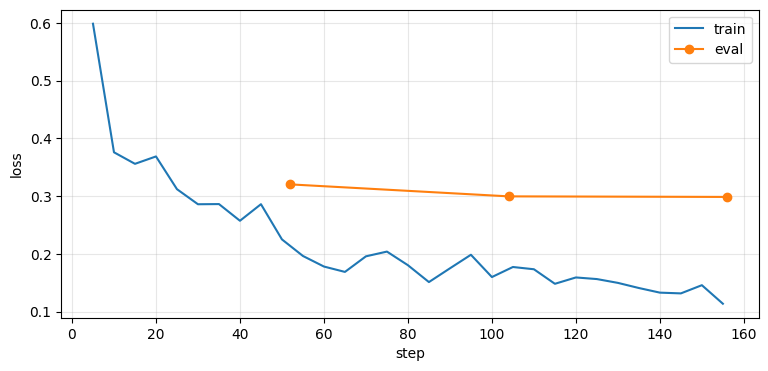

In [21]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="eval")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Результат обучения

За 3 эпохи train loss снизился с 0.5985 до 0.1135 (первое и последнее логирование), а validation loss — с 0.3202 после первой эпохи до 0.2985 после третьей. На валидации улучшение к концу небольшое. Train loss продолжает снижаться, но этого недостаточно, чтобы судить о качестве вызовов: отдельно проверяем функции и аргументы на тесте. Обучение заняло 109 секунд на A100.

Обучение завершилось на шаге 156: 52 шага на эпоху, эффективный batch size 16. Использован AdamW, линейное снижение learning rate с 2e-5 до нуля, без warmup, clipping градиента 1.0. В записанных значениях loss и grad norm нет NaN/Inf; norm до clipping лежит в диапазоне 3.22–13.63. Все 494 032 768 параметров обучаемые, LoRA не используется. Это один выбранный конфиг, а не результат подбора оптимальных гиперпараметров.

Train loss снижается заметно сильнее validation loss: к третьей эпохе появляется разрыв, а улучшение на validation почти заканчивается. Поэтому дальнейшее обучение без новой проверки не обосновано. Проверены все 922 диалога: маски непустые, токены user/system/tool исключены, максимальная длина 1285 — обрезания до 2048 не было.


## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [22]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [23]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()  # trainer мог оставить модель в train-режиме

cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")
scores = pd.concat([
    summarize(evaluate(base_model, tokenizer, cases)).assign(model="base"),
    summarize(evaluate(model, tokenizer, cases)).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
del base_model
gc.collect()
torch.cuda.empty_cache()

scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.75,0.55
1,base,ru,0.75,0.20
2,sft,en,0.95,0.90
3,sft,ru,0.85,0.80


### Разбор результатов

Повторная проверка дала те же метрики: exact match 22/40 → 36/40 для EN и 4/20 → 16/20 для RU; tool set accuracy 30/40 → 38/40 и 15/20 → 17/20. Base заново загружена из исходного checkpoint, SFT проверена по сохранённым весам. Все десять исходных ответов base воспроизвелись.

Tool set accuracy сравнивает множества имён функций и не учитывает число повторных вызовов. Exact match сравнивает отсортированные списки вызовов с аргументами, сохраняя повторы; пропущенное quantity=1 приравнивается к явному. Строковые значения сравниваются точно. Для no-call эти метрики проверяют отсутствие вызовов, а не качество текста ответа.

Остались 8 ошибок SFT: en_03 и en_16 — лишние уточнения; en_11 — три отдельных lemon вместо lemons с quantity=3; en_14 — 120 минут вместо 60; ru_07 — кефир и лишний калькулятор вместо двух пакетов кефира; ru_09 — уточнение вместо выключения света везде; ru_16 и ru_17 — включение света в гостиной вместо отказа для телевизора и ванной. В сравнении до/после два пакета молока тоже добавляются двумя вызовами по одному: суммарное количество совпадает, но структура списка и вызовов отличается от одного quantity=2.

Полных одинаковых диалогов в train и validation нет, но есть общие короткие реплики. В 7 из 60 тестовых примеров встречаются пользовательские фразы из train (en_16, en_17, en_22, en_25, en_33, en_40, ru_13); в двух из них совпадает лишь часть многоходового контекста. Поэтому тест не полностью независим, а результаты на небольшом наборе нельзя переносить на произвольные запросы. Данные и метрики после аудита не менялись.


Те же десять запросов: base-модель и обученная.

In [24]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
with pd.option_context("display.max_colwidth", None):
    display(comparison)

prompt,base,after_sft
Turn on the kitchen light.,"<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}} </tool_call>","<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}} </tool_call>"
Set the bedroom to 23 degrees.,"<tool_call> {""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}} </tool_call>","<tool_call> {""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}} </tool_call>"
What is the state of the living room?,"<tool_call> {""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}} </tool_call>","<tool_call> {""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}} </tool_call>"
Add two cartons of milk to my shopping list.,"<tool_call> {""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}} </tool_call>","<tool_call> {""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk""}} </tool_call> <tool_call> {""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk""}} </tool_call>"
Set a 10-minute timer labeled pasta.,"<tool_call> {""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}} </tool_call>","<tool_call> {""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}} </tool_call>"
Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}} </tool_call> <tool_call> {""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}} </tool_call>","<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}} </tool_call> <tool_call> {""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}} </tool_call>"
Turn off all lights.,"<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}} </tool_call>","<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}} </tool_call> <tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}} </tool_call> <tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}} </tool_call>"
Hello!,How can I help you today?,Hello! How can I help you?
Open the garage.,"<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}} </tool_call>","I can't control the garage. I can handle lights, temperature, the shopping list and timers."
Turn on the light.,"<tool_call> {""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}} </tool_call>",Which room should I turn it on in?


## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [25]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    for _ in range(max_steps):
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        if calls is None:
            raise ValueError("Некорректный формат tool_call")
        if not calls:
            messages.append({"role": "assistant", "content": output})
            return

        messages.append({
            "role": "assistant",
            "content": TOOL_CALL_PATTERN.sub("", output).strip(),
            "tool_calls": [{"type": "function", "function": call} for call in calls],
        })
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({
                "role": "tool",
                "name": call["name"],
                "content": json.dumps(result, ensure_ascii=False),
            })


In [26]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
for prompts in scenarios:
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(home.snapshot(), ensure_ascii=False)}")

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's at 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Make it two degrees warmer in the bedroom.
[assistant] Which degree should I set?
[user] Two more degrees.
[assistant] 
    -> get_room_state({"room": "bedroom"})
[tool] {"room": "bedroom", "light": "off", "temperature": 21}
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 23})
[tool] {"room": "bedroom", "light": "off", "temperature": 23}
[assistant] The bedroom is now at 23 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 23}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Thanks!
[assistant] You're welcome! If you have any other questions, feel free to ask.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Open the garage.
[assistant] I can't control the garage. I can handle lights, temperature, the shopping list and timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


### Проверка агентных сценариев

Четыре сценария соответствуют запросам: свет включён; свет включён и температура выставлена на 23; на благодарность нет вызовов; для гаража дан отказ. Сценарий с двумя последовательными повышениями температуры прошёл неполно: на первый запрос модель уточнила уже заданную величину, а после второго повысила температуру с 21 до 23 вместо ожидаемых 25. Завершение ячейки не означает успех этого сценария.

В чате проверены отправка запроса, реальный вызов turn_light, обновление панели дома и сброс. Ограничение цикла — максимум четыре генерации; при исчерпании лимита отдельного сообщения об этом нет.


Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [27]:
launch_chat(model, tokenizer, SmartHome(), run_agent)